# gambar 2.1

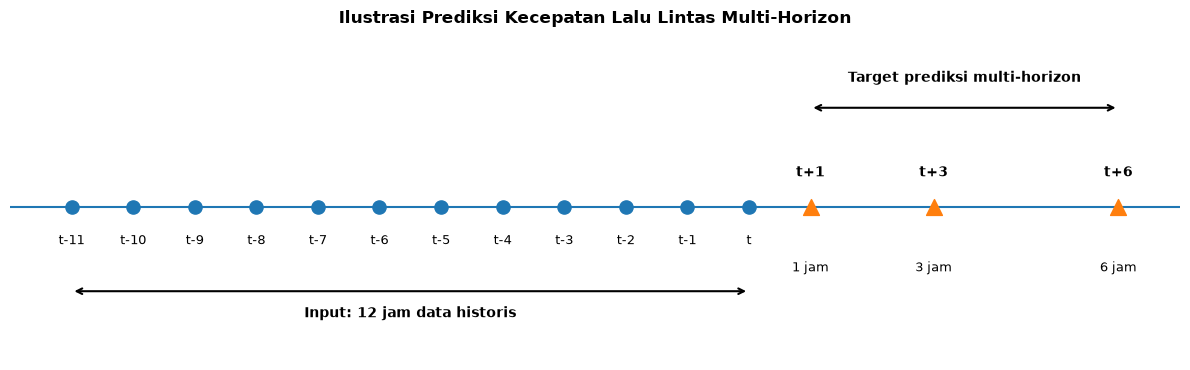

In [1]:
import matplotlib.pyplot as plt

# Timeline:
# 12 historical timesteps = t-11 sampai t
history = list(range(-11, 1))
targets = [1, 3, 6]

fig, ax = plt.subplots(figsize=(12, 3.8))

# Garis timeline
ax.axhline(0, linewidth=1.5)

# Input historis
ax.scatter(history, [0] * len(history), s=90, zorder=3)

# Target prediksi
ax.scatter(targets, [0] * len(targets), s=130, marker="^", zorder=3)

# Label timestep historis
for x in history:
    if x == 0:
        label = "t"
    else:
        label = f"t{x}"

    ax.text(x, -0.18, label, ha="center", va="top", fontsize=9)

# Label target
for x in targets:
    ax.text(x, 0.18, f"t+{x}", ha="center", va="bottom", fontsize=10, fontweight="bold")

# Penanda area input
ax.annotate(
    "", xy=(-11, -0.55), xytext=(0, -0.55), arrowprops=dict(arrowstyle="<->", linewidth=1.5)
)

ax.text(-5.5, -0.72, "Input: 12 jam data historis", ha="center", fontsize=10, fontweight="bold")

# Penanda area prediksi
ax.annotate("", xy=(1, 0.65), xytext=(6, 0.65), arrowprops=dict(arrowstyle="<->", linewidth=1.5))

ax.text(3.5, 0.82, "Target prediksi multi-horizon", ha="center", fontsize=10, fontweight="bold")

# Keterangan horizon
ax.text(1, -0.42, "1 jam", ha="center", fontsize=9)
ax.text(3, -0.42, "3 jam", ha="center", fontsize=9)
ax.text(6, -0.42, "6 jam", ha="center", fontsize=9)

ax.set_xlim(-12, 7)
ax.set_ylim(-1.0, 1.15)

ax.set_title(
    "Ilustrasi Prediksi Kecepatan Lalu Lintas Multi-Horizon", fontsize=12, fontweight="bold"
)

ax.axis("off")

plt.tight_layout()

plt.savefig("multi_horizon_forecasting.png", dpi=300, bbox_inches="tight")

plt.show()

### Ilustrasi Spatial dan Temporal Dependency

Gambar berikut dibuat untuk mengilustrasikan dua jenis dependensi yang terdapat pada data lalu lintas, yaitu **temporal dependency** dan **spatial dependency**.

Pada **temporal dependency**, kondisi lalu lintas pada suatu corridor berkaitan dengan kondisi historis pada corridor yang sama. Dalam penelitian ini, setiap node menggunakan 12 timestep historis, yaitu dari $t-11$ hingga $t$.

Pada **spatial dependency**, kondisi lalu lintas pada suatu corridor dapat memiliki keterkaitan dengan corridor lain yang direpresentasikan sebagai node pada traffic graph. Hubungan antar-node tersebut memungkinkan model memanfaatkan informasi spasial dalam melakukan prediksi kecepatan lalu lintas.

Visualisasi ini digunakan sebagai ilustrasi konseptual dan tidak menunjukkan hasil prediksi model.

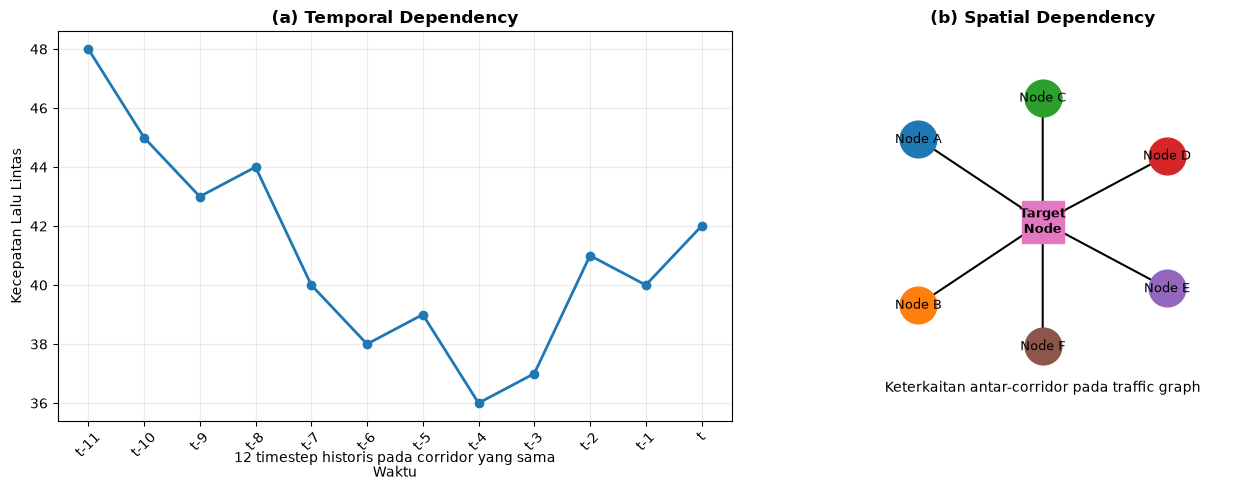

In [2]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ============================================================
# (a) TEMPORAL DEPENDENCY
# ============================================================

ax = axes[0]

# 12 timestep historis: t-11 sampai t
time = np.arange(-11, 1)

# Nilai hanya untuk ilustrasi konsep
speed = np.array([48, 45, 43, 44, 40, 38, 39, 36, 37, 41, 40, 42])

ax.plot(time, speed, marker="o", linewidth=2)

ax.set_xticks(time)
ax.set_xticklabels([f"t{x}" if x < 0 else "t" for x in time], rotation=45)

ax.set_xlabel("Waktu")
ax.set_ylabel("Kecepatan Lalu Lintas")
ax.set_title("(a) Temporal Dependency", fontweight="bold")

ax.text(-5.5, 34, "12 timestep historis pada corridor yang sama", ha="center", fontsize=10)

ax.grid(alpha=0.25)


# ============================================================
# (b) SPATIAL DEPENDENCY
# ============================================================

ax = axes[1]

# Posisi node untuk ilustrasi
positions = {
    "Node A": (-1.5, 1.0),
    "Node B": (-1.5, -1.0),
    "Node C": (0.0, 1.5),
    "Node D": (1.5, 0.8),
    "Target\nNode": (0.0, 0.0),
    "Node E": (1.5, -0.8),
    "Node F": (0.0, -1.5),
}

target = positions["Target\nNode"]

# Hubungkan corridor lain ke target node
for name, pos in positions.items():
    if name != "Target\nNode":
        ax.annotate("", xy=target, xytext=pos, arrowprops=dict(arrowstyle="->", linewidth=1.5))

# Neighbor nodes
for name, (x, y) in positions.items():
    if name != "Target\nNode":
        ax.scatter(x, y, s=700, zorder=3)
        ax.text(x, y, name, ha="center", va="center", fontsize=9, zorder=4)

# Target node dibuat berbeda bentuk
ax.scatter(target[0], target[1], s=900, marker="s", zorder=5)

ax.text(
    target[0],
    target[1],
    "Target\nNode",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold",
    zorder=6,
)

ax.set_title("(b) Spatial Dependency", fontweight="bold")

ax.text(0, -2.05, "Keterkaitan antar-corridor pada traffic graph", ha="center", fontsize=10)

ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.4, 2.3)
ax.set_aspect("equal")
ax.axis("off")


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout()

plt.savefig("spatial_temporal_dependency.png", dpi=300, bbox_inches="tight")

plt.show()

### Gambar 2.3 Representasi Jaringan Lalu Lintas Menjadi Struktur Graph

Visualisasi berikut menunjukkan proses representasi jaringan lalu lintas menjadi traffic graph pada penelitian. Panel kiri menampilkan lokasi geografis corridor berdasarkan koordinat yang digunakan pada dataset penelitian. Panel kanan menunjukkan abstraksi lokasi tersebut menjadi struktur graph, dengan setiap corridor direpresentasikan sebagai **node** dan hubungan geografis antar-corridor direpresentasikan sebagai **edge**.

Hubungan pada panel graph menggunakan **Fixed Graph** penelitian yang dibentuk berdasarkan kedekatan geografis dengan metode **K-Nearest Neighbors (KNN), K=4**. Visualisasi ini menunjukkan bahwa informasi geografis jaringan lalu lintas dapat direpresentasikan dalam bentuk graph sebelum digunakan sebagai input spasial pada Graph WaveNet.

Project root: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent
Jumlah corridor: 64
   node_index  corridor_name  latitude  longitude
0           0         Cawang   -6.2450    106.865
1           1  Gatot Subroto   -6.2349    106.830
2           2         Grogol   -6.1660    106.790
3           3  Kelapa Gading   -6.1580    106.906
4           4       Kuningan   -6.2210    106.830
Adjacency shape: (64, 64)
Directed edges: 320


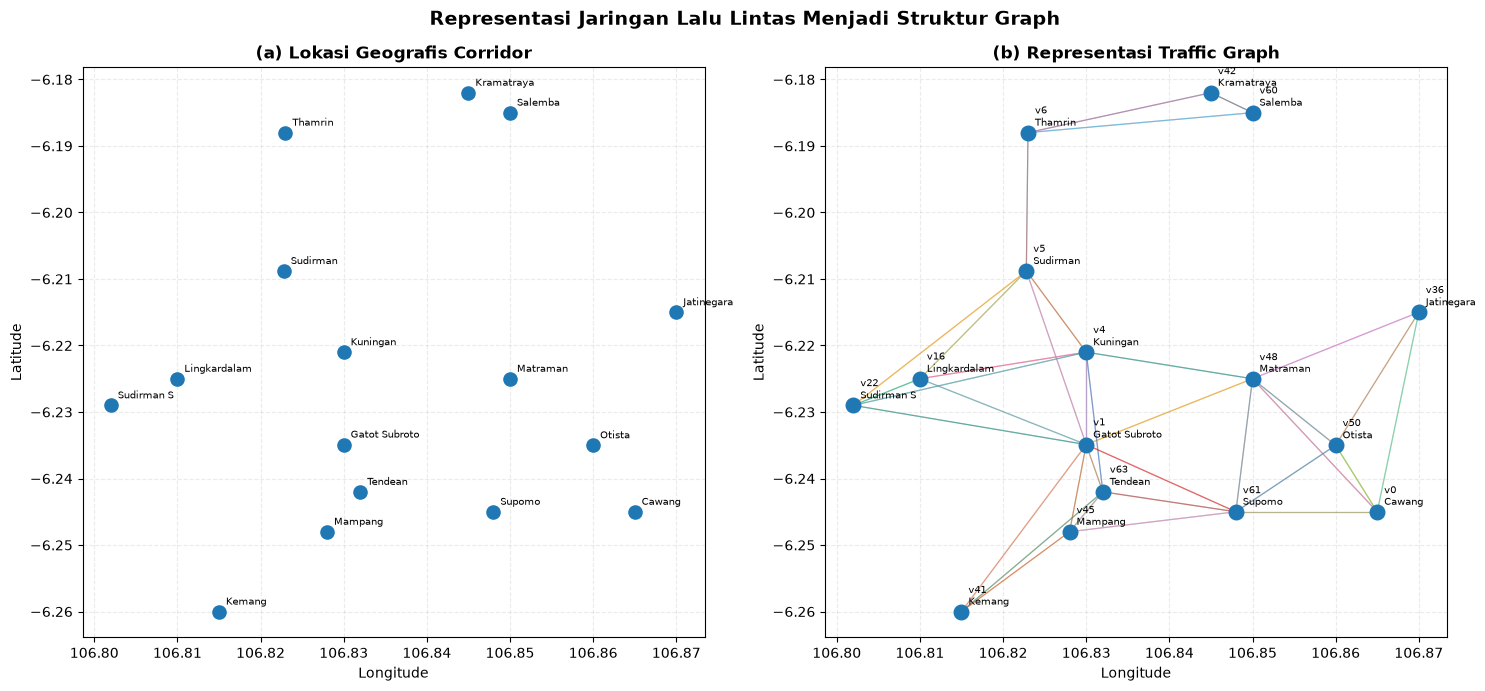


Gambar disimpan di:
/Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/traffic_network_to_graph.png


In [4]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. CARI ROOT PROJECT
# ============================================================

current = Path.cwd().resolve()
project_root = current

while not (project_root / "streamlit_app").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError(
            "Root project yang memiliki folder 'streamlit_app' tidak ditemukan."
        )
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


# ============================================================
# 2. LOAD METADATA CORRIDOR
# ============================================================

from streamlit_app.data_loader import get_corridor_metadata

corridor_df = get_corridor_metadata().sort_values("node_index").reset_index(drop=True)

required_columns = {
    "node_index",
    "corridor_name",
    "latitude",
    "longitude",
}

missing = required_columns - set(corridor_df.columns)

if missing:
    raise ValueError(f"Kolom metadata yang dibutuhkan tidak ditemukan: {missing}")

print("Jumlah corridor:", len(corridor_df))
print(corridor_df[["node_index", "corridor_name", "latitude", "longitude"]].head())


# ============================================================
# 3. LOAD FIXED GRAPH ASLI
# ============================================================

graph_path = project_root / "outputs" / "final_64" / "fixed_graph" / "fixed_graph_64.npz"

graph_data = np.load(graph_path)

adjacency = graph_data["adjacency"]

print("Adjacency shape:", adjacency.shape)
print("Directed edges:", int(np.count_nonzero(adjacency)))


# ============================================================
# 4. AMBIL SUBSET UNTUK VISUALISASI
# ============================================================
# Supaya gambar tidak terlalu penuh, tampilkan 16 corridor
# dari subset geografis yang sudah digunakan pada eksperimen scalability.

selected_nodes = [
    4,
    1,
    5,
    48,
    16,
    63,
    45,
    22,
    61,
    50,
    6,
    36,
    60,
    41,
    42,
    0,
]

subset = (
    corridor_df[corridor_df["node_index"].isin(selected_nodes)]
    .set_index("node_index")
    .loc[selected_nodes]
    .reset_index()
)

selected_set = set(selected_nodes)


# ============================================================
# 5. BUAT FIGURE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 7))


# ============================================================
# PANEL A — POSISI GEOGRAFIS CORRIDOR
# ============================================================

ax = axes[0]

ax.scatter(
    subset["longitude"],
    subset["latitude"],
    s=90,
    zorder=3,
)

for _, row in subset.iterrows():
    ax.annotate(
        row["corridor_name"],
        (
            row["longitude"],
            row["latitude"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7,
    )

ax.set_title(
    "(a) Lokasi Geografis Corridor",
    fontweight="bold",
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid(
    alpha=0.25,
    linestyle="--",
)


# ============================================================
# PANEL B — ABSTRAKSI MENJADI TRAFFIC GRAPH
# ============================================================

ax = axes[1]

# Gambar edge Fixed Graph yang kedua node-nya
# berada dalam subset visualisasi.
for i in selected_nodes:
    for j in selected_nodes:
        if adjacency[i, j] > 0:
            source = subset[subset["node_index"] == i].iloc[0]

            target = subset[subset["node_index"] == j].iloc[0]

            ax.plot(
                [
                    source["longitude"],
                    target["longitude"],
                ],
                [
                    source["latitude"],
                    target["latitude"],
                ],
                linewidth=0.9,
                alpha=0.45,
                zorder=1,
            )


# Gambar node
ax.scatter(
    subset["longitude"],
    subset["latitude"],
    s=110,
    zorder=3,
)


# Label node
for _, row in subset.iterrows():
    ax.annotate(
        f"v{int(row['node_index'])}\n{row['corridor_name']}",
        (
            row["longitude"],
            row["latitude"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7,
    )


ax.set_title(
    "(b) Representasi Traffic Graph",
    fontweight="bold",
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid(
    alpha=0.25,
    linestyle="--",
)


# ============================================================
# FINAL
# ============================================================

fig.suptitle(
    "Representasi Jaringan Lalu Lintas Menjadi Struktur Graph",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()

output_path = project_root / "traffic_network_to_graph.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nGambar disimpan di:")
print(output_path)

In [5]:
print("Diagonal non-zero:", np.count_nonzero(np.diag(adjacency)))
print("Edges tanpa diagonal:", np.count_nonzero(adjacency) - np.count_nonzero(np.diag(adjacency)))

Diagonal non-zero: 0
Edges tanpa diagonal: 320


### Gambar 2.6 Perbandingan Fixed, Adaptive, dan Hybrid Graph

Visualisasi berikut membandingkan tiga strategi representasi graph yang digunakan dalam penelitian, yaitu **Fixed Graph, Adaptive Graph, dan Hybrid Graph**. Ketiga konfigurasi menggunakan kumpulan node yang sama, tetapi berbeda dalam cara hubungan antar-node direpresentasikan.

Pada **Fixed Graph**, edge dibentuk berdasarkan kedekatan geografis antar-node. Pada **Adaptive Graph**, hubungan antar-node dipelajari dari data selama proses training dan merepresentasikan **learned dependency**, sehingga edge tidak diinterpretasikan sebagai jalur jalan secara fisik. Sementara itu, **Hybrid Graph** menggunakan informasi dari Fixed Graph dan Adaptive Graph secara bersamaan.

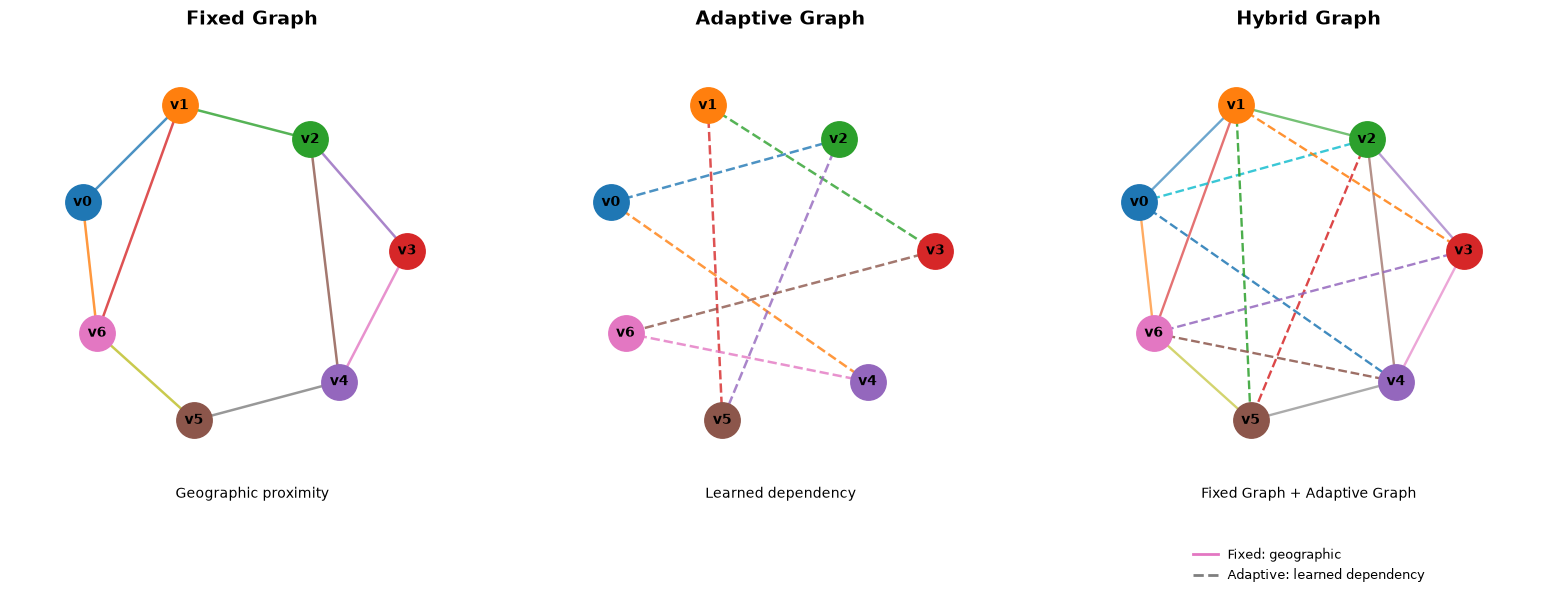

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# POSISI NODE
# Posisi dibuat sama untuk ketiga panel agar perbedaannya
# hanya berasal dari strategi pembentukan edge.
# ============================================================

pos = {
    0: (0.15, 0.65),
    1: (0.35, 0.85),
    2: (0.62, 0.78),
    3: (0.82, 0.55),
    4: (0.68, 0.28),
    5: (0.38, 0.20),
    6: (0.18, 0.38),
}

# ============================================================
# EDGE FIXED GRAPH
# Ilustrasi hubungan berdasarkan kedekatan geografis
# ============================================================

fixed_edges = [
    (0, 1),
    (0, 6),
    (1, 2),
    (1, 6),
    (2, 3),
    (2, 4),
    (3, 4),
    (4, 5),
    (5, 6),
]

# ============================================================
# EDGE ADAPTIVE GRAPH
# Ilustrasi learned dependency.
# BUKAN representasi jalan fisik.
# ============================================================

adaptive_edges = [
    (0, 2),
    (0, 4),
    (1, 3),
    (1, 5),
    (2, 5),
    (3, 6),
    (4, 6),
]


# ============================================================
# FUNGSI MENGGAMBAR NODE
# ============================================================


def draw_nodes(ax):

    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=650, zorder=5)

        ax.text(
            x, y, f"v{node}", ha="center", va="center", fontsize=10, fontweight="bold", zorder=6
        )


# ============================================================
# FUNGSI MENGGAMBAR EDGE
# ============================================================


def draw_edges(ax, edges, linestyle="-", linewidth=1.8, alpha=0.8):

    for source, target in edges:
        x1, y1 = pos[source]
        x2, y2 = pos[target]

        ax.plot([x1, x2], [y1, y2], linestyle=linestyle, linewidth=linewidth, alpha=alpha, zorder=2)


# ============================================================
# MEMBUAT FIGURE
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))


# ============================================================
# PANEL 1 — FIXED GRAPH
# ============================================================

ax = axes[0]

draw_edges(ax, fixed_edges, linestyle="-")

draw_nodes(ax)

ax.set_title("Fixed Graph", fontsize=14, fontweight="bold")

ax.text(0.5, 0.04, "Geographic proximity", transform=ax.transAxes, ha="center", fontsize=10)


# ============================================================
# PANEL 2 — ADAPTIVE GRAPH
# ============================================================

ax = axes[1]

draw_edges(ax, adaptive_edges, linestyle="--")

draw_nodes(ax)

ax.set_title("Adaptive Graph", fontsize=14, fontweight="bold")

ax.text(0.5, 0.04, "Learned dependency", transform=ax.transAxes, ha="center", fontsize=10)


# ============================================================
# PANEL 3 — HYBRID GRAPH
# ============================================================

ax = axes[2]

# Fixed graph = garis penuh
draw_edges(ax, fixed_edges, linestyle="-", linewidth=1.7, alpha=0.65)

# Adaptive graph = garis putus-putus
draw_edges(ax, adaptive_edges, linestyle="--", linewidth=1.7, alpha=0.85)

draw_nodes(ax)

ax.set_title("Hybrid Graph", fontsize=14, fontweight="bold")

ax.text(0.5, 0.04, "Fixed Graph + Adaptive Graph", transform=ax.transAxes, ha="center", fontsize=10)


# ============================================================
# FORMAT SEMUA PANEL
# ============================================================

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_aspect("equal")

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# ============================================================
# LEGEND KHUSUS HYBRID
# ============================================================

axes[2].plot([], [], linestyle="-", linewidth=2, label="Fixed: geographic")

axes[2].plot([], [], linestyle="--", linewidth=2, label="Adaptive: learned dependency")

axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), frameon=False, fontsize=9)


# ============================================================
# SAVE
# ============================================================

plt.tight_layout()

plt.savefig("fixed_adaptive_hybrid_graph.png", dpi=300, bbox_inches="tight")

plt.show()

### Gambar 2.7 Arsitektur GC-LSTM-style Baseline

Visualisasi berikut menunjukkan arsitektur **GC-LSTM-style baseline** yang digunakan sebagai model pembanding dalam penelitian. Model menerima input data kecepatan lalu lintas dari beberapa node atau corridor selama **12 langkah waktu historis**. Informasi spasial terlebih dahulu diproses menggunakan **Fixed Graph Propagation**, kemudian dilakukan transformasi fitur menggunakan **Dense layer**.

Fitur graph dari setiap langkah waktu selanjutnya diproses oleh **Long Short-Term Memory (LSTM)** untuk mempelajari dependency temporal. Representasi yang dihasilkan LSTM diteruskan ke **Dense Output** untuk menghasilkan prediksi kecepatan lalu lintas pada tiga horizon, yaitu **t+1, t+3, dan t+6 jam**. Diagram ini menggambarkan implementasi baseline pada penelitian dan bukan reproduksi identik dari arsitektur GC-LSTM pada penelitian terdahulu.

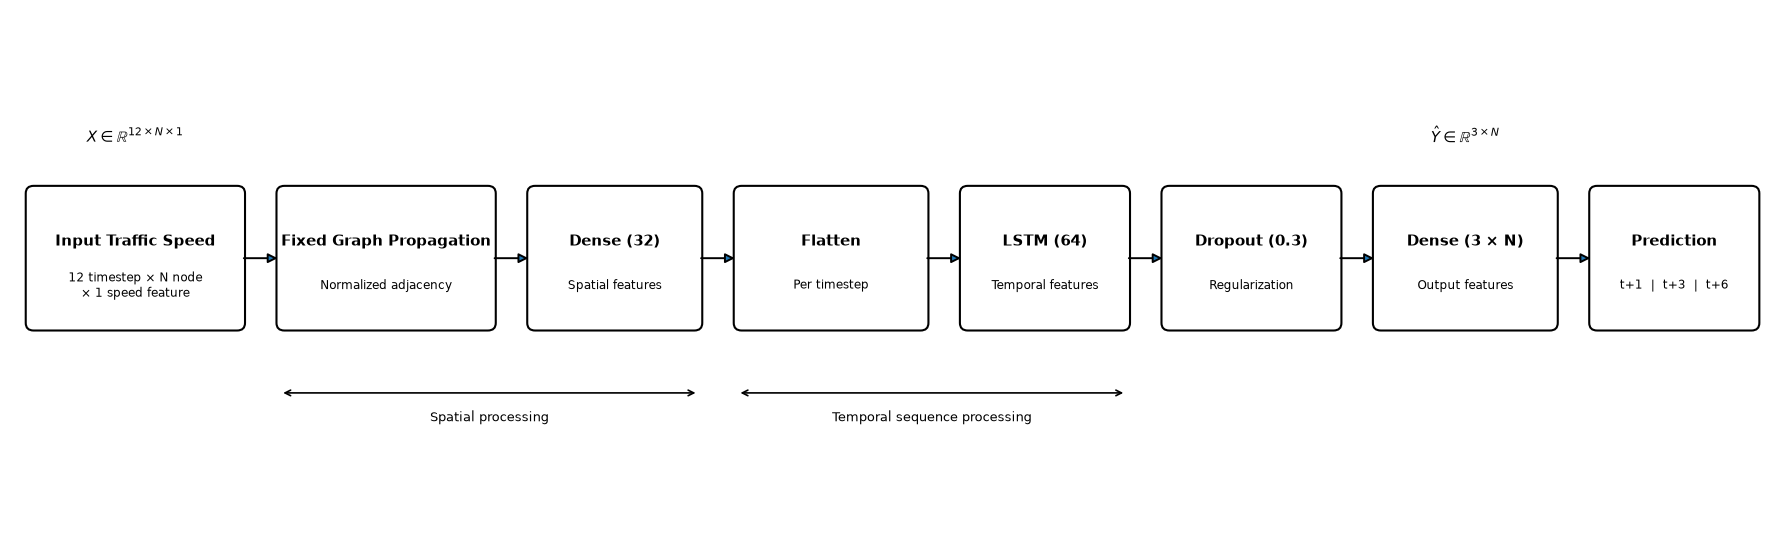

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ============================================================
# SETUP
# ============================================================

fig, ax = plt.subplots(figsize=(18, 5.5))

ax.set_xlim(0, 18)
ax.set_ylim(0, 5.5)
ax.axis("off")


# ============================================================
# HELPER FUNCTIONS
# ============================================================


def add_box(x, y, w, h, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.04,rounding_size=0.08",
        linewidth=1.5,
        facecolor="white",
        edgecolor="black",
    )
    ax.add_patch(box)

    ax.text(
        x + w / 2, y + h * 0.62, title, ha="center", va="center", fontsize=10.5, fontweight="bold"
    )

    if subtitle:
        ax.text(x + w / 2, y + h * 0.30, subtitle, ha="center", va="center", fontsize=8.5)


def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, linewidth=1.4)
    ax.add_patch(arrow)


# ============================================================
# BOX POSITIONS
# ============================================================

y = 2.15
h = 1.45

boxes = [
    # x, width, title, subtitle
    (0.2, 2.15, "Input Traffic Speed", "12 timestep × N node\n× 1 speed feature"),
    (2.75, 2.15, "Fixed Graph Propagation", "Normalized adjacency"),
    (5.30, 1.70, "Dense (32)", "Spatial features"),
    (7.40, 1.90, "Flatten", "Per timestep"),
    (9.70, 1.65, "LSTM (64)", "Temporal features"),
    (11.75, 1.75, "Dropout (0.3)", "Regularization"),
    (13.90, 1.80, "Dense (3 × N)", "Output features"),
    (16.10, 1.65, "Prediction", "t+1  |  t+3  |  t+6"),
]


# ============================================================
# DRAW BOXES
# ============================================================

for x, w, title, subtitle in boxes:
    add_box(x, y, w, h, title, subtitle)


# ============================================================
# DRAW ARROWS
# ============================================================

center_y = y + h / 2

for i in range(len(boxes) - 1):
    x_current = boxes[i][0]
    w_current = boxes[i][1]

    x_next = boxes[i + 1][0]

    add_arrow(x_current + w_current, center_y, x_next, center_y)


# ============================================================
# SPATIAL PROCESSING LABEL
# ============================================================

ax.annotate(
    "", xy=(2.75, 1.45), xytext=(7.0, 1.45), arrowprops=dict(arrowstyle="<->", linewidth=1.2)
)

ax.text(4.875, 1.15, "Spatial processing", ha="center", fontsize=9.5)


# ============================================================
# TEMPORAL PROCESSING LABEL
# ============================================================

ax.annotate(
    "", xy=(7.40, 1.45), xytext=(11.35, 1.45), arrowprops=dict(arrowstyle="<->", linewidth=1.2)
)

ax.text(9.375, 1.15, "Temporal sequence processing", ha="center", fontsize=9.5)


# ============================================================
# INPUT SHAPE
# ============================================================

ax.text(1.275, 4.10, r"$X \in \mathbb{R}^{12 \times N \times 1}$", ha="center", fontsize=11)


# ============================================================
# OUTPUT SHAPE
# ============================================================

ax.text(14.80, 4.10, r"$\hat{Y} \in \mathbb{R}^{3 \times N}$", ha="center", fontsize=11)


# ============================================================
# SAVE
# ============================================================

plt.tight_layout()

plt.savefig("arsitektur_gclstm_baseline.png", dpi=300, bbox_inches="tight")

plt.show()

### Gambar 3.1 Alur Penelitian

Flowchart berikut menggambarkan tahapan penelitian mulai dari pengolahan data TomTom hingga analisis hasil. Data lalu lintas terlebih dahulu melalui tahap preprocessing dan dibentuk menjadi dataset multi-horizon dengan 12 jam data historis sebagai input serta target prediksi pada horizon t+1, t+3, dan t+6 jam.

Selanjutnya, traffic graph dibentuk untuk digunakan pada Graph WaveNet dengan tiga strategi representasi graph, yaitu Fixed, Adaptive, dan Hybrid. GC-LSTM-style digunakan sebagai model pembanding. Model kemudian melalui proses training dan evaluasi menggunakan MAE, RMSE, serta pengujian multi-seed. Evaluasi juga mencakup karakteristik komputasional dan scalability pada ukuran graph 8, 16, 32, dan 64 node sebelum dilakukan analisis hasil keseluruhan.

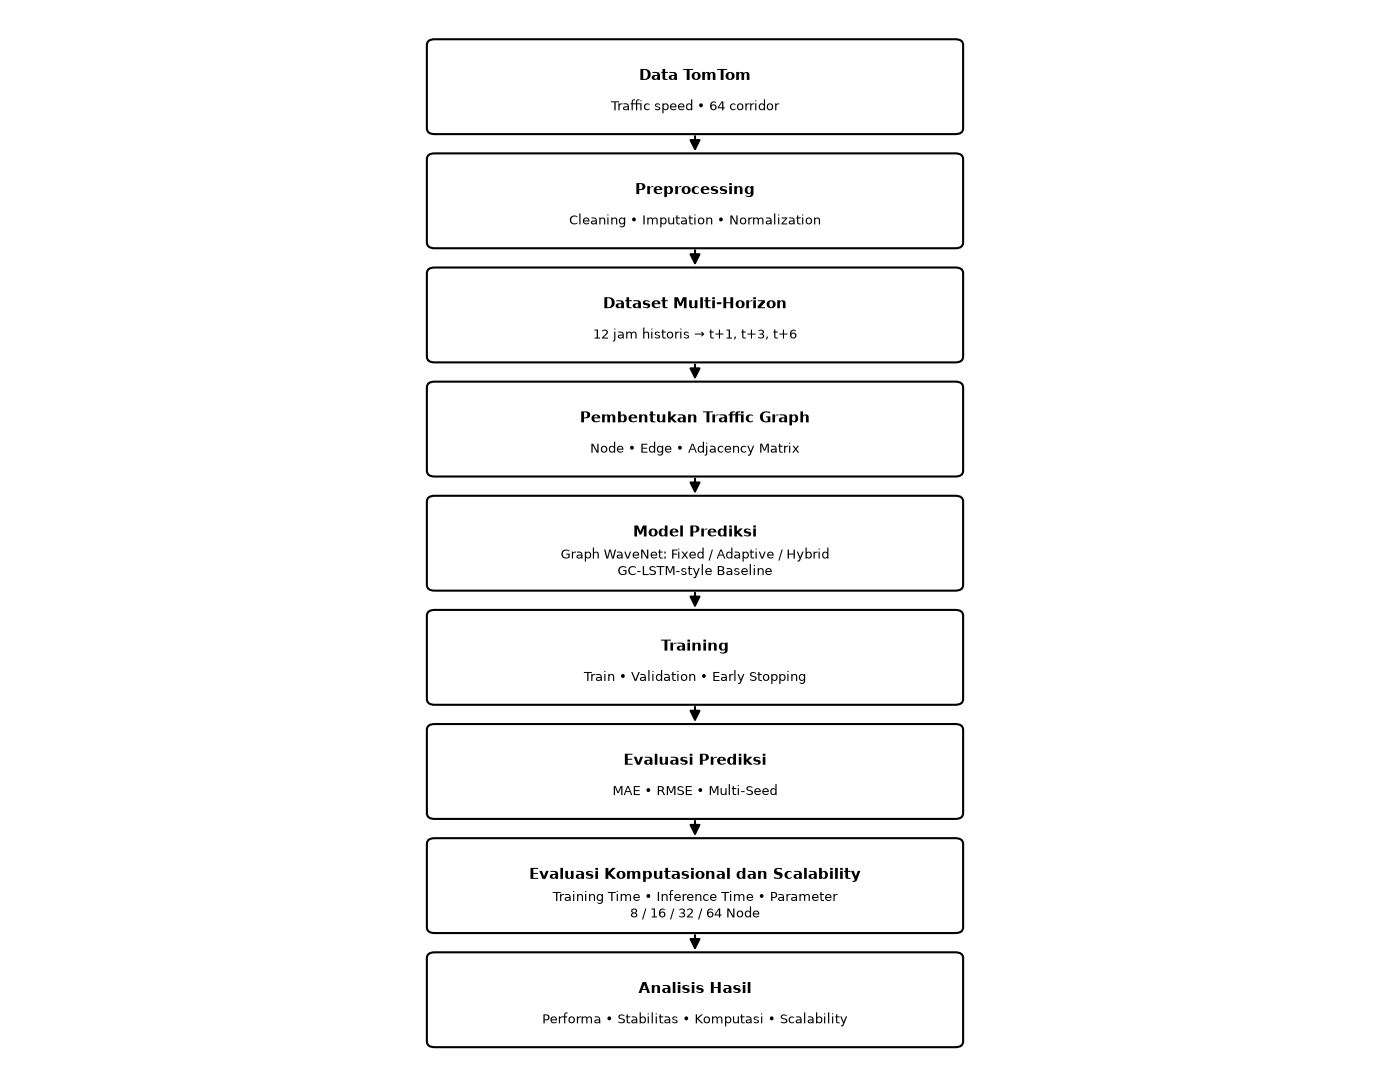

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ============================================================
# SETUP FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(14, 11))

ax.set_xlim(0, 14)
ax.set_ylim(0, 15)
ax.axis("off")


# ============================================================
# HELPER: FLOWCHART BOX
# ============================================================


def add_box(x, y, w, h, title, subtitle=None):
    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.04,rounding_size=0.08",
        linewidth=1.5,
        facecolor="white",
        edgecolor="black",
    )

    ax.add_patch(box)

    if subtitle:
        ax.text(
            x + w / 2, y + h * 0.62, title, ha="center", va="center", fontsize=11, fontweight="bold"
        )

        ax.text(x + w / 2, y + h * 0.28, subtitle, ha="center", va="center", fontsize=9)

    else:
        ax.text(
            x + w / 2, y + h / 2, title, ha="center", va="center", fontsize=11, fontweight="bold"
        )


# ============================================================
# HELPER: ARROW
# ============================================================


def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=16, linewidth=1.5, color="black"
    )

    ax.add_patch(arrow)


# ============================================================
# UKURAN BOX
# ============================================================

w = 5.4
h = 1.25
x = 4.3

# Posisi dari atas ke bawah
ys = [13.3, 11.7, 10.1, 8.5, 6.9, 5.3, 3.7, 2.1, 0.5]


# ============================================================
# 1. DATA TOMTOM
# ============================================================

add_box(x, ys[0], w, h, "Data TomTom", "Traffic speed • 64 corridor")


# ============================================================
# 2. PREPROCESSING
# ============================================================

add_box(x, ys[1], w, h, "Preprocessing", "Cleaning • Imputation • Normalization")


# ============================================================
# 3. MULTI-HORIZON DATASET
# ============================================================

add_box(x, ys[2], w, h, "Dataset Multi-Horizon", "12 jam historis → t+1, t+3, t+6")


# ============================================================
# 4. TRAFFIC GRAPH
# ============================================================

add_box(x, ys[3], w, h, "Pembentukan Traffic Graph", "Node • Edge • Adjacency Matrix")


# ============================================================
# 5. MODEL
# ============================================================

add_box(
    x,
    ys[4],
    w,
    h,
    "Model Prediksi",
    "Graph WaveNet: Fixed / Adaptive / Hybrid\nGC-LSTM-style Baseline",
)


# ============================================================
# 6. TRAINING
# ============================================================

add_box(x, ys[5], w, h, "Training", "Train • Validation • Early Stopping")


# ============================================================
# 7. EVALUASI PREDIKSI
# ============================================================

add_box(x, ys[6], w, h, "Evaluasi Prediksi", "MAE • RMSE • Multi-Seed")


# ============================================================
# 8. KOMPUTASI + SCALABILITY
# ============================================================

add_box(
    x,
    ys[7],
    w,
    h,
    "Evaluasi Komputasional dan Scalability",
    "Training Time • Inference Time • Parameter\n8 / 16 / 32 / 64 Node",
)


# ============================================================
# 9. ANALISIS HASIL
# ============================================================

add_box(x, ys[8], w, h, "Analisis Hasil", "Performa • Stabilitas • Komputasi • Scalability")


# ============================================================
# ARROWS
# ============================================================

for i in range(len(ys) - 1):
    # bawah box sekarang
    start_x = x + w / 2
    start_y = ys[i]

    # atas box berikutnya
    end_x = x + w / 2
    end_y = ys[i + 1] + h

    add_arrow(start_x, start_y - 0.03, end_x, end_y + 0.03)


# ============================================================
# SAVE
# ============================================================

plt.tight_layout()

plt.savefig("alur_penelitian.png", dpi=300, bbox_inches="tight")

plt.show()

### Pembentukan Input dan Target Prediksi Multi-Horizon

Visualisasi berikut menunjukkan proses pembentukan data multi-horizon yang digunakan dalam penelitian. Setiap sampel menggunakan **12 observasi historis**, mulai dari $t-11$ hingga $t$, sebagai input model. Pada setiap timestep terdapat data **traffic speed dari 64 node atau corridor**.

Berdasarkan rangkaian data historis tersebut, target prediksi dibentuk pada tiga horizon waktu, yaitu **$t+1$, $t+3$, dan $t+6$**, yang masing-masing merepresentasikan prediksi kecepatan lalu lintas 1 jam, 3 jam, dan 6 jam ke depan.

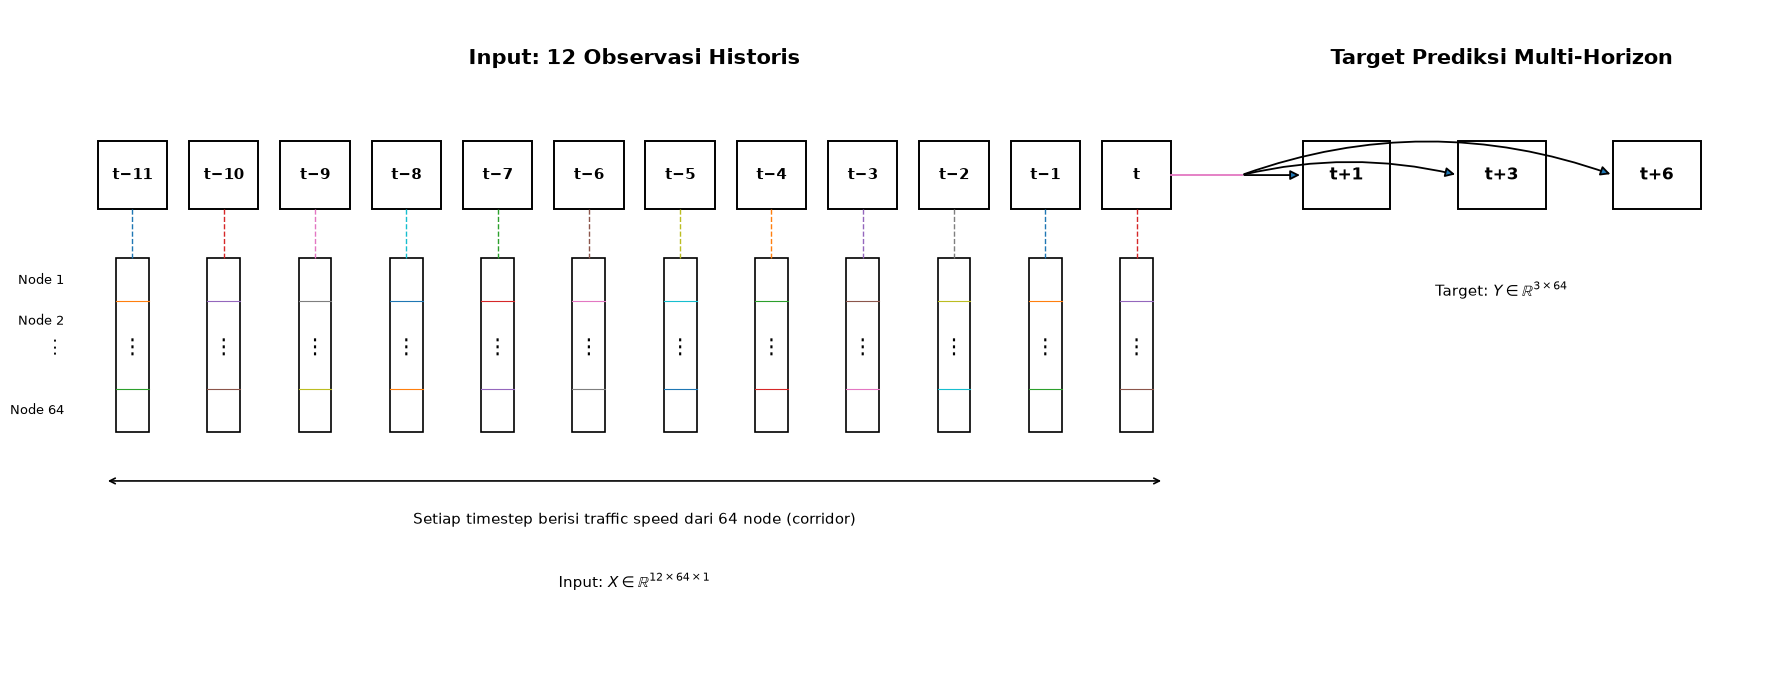

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# ============================================================
# SETUP
# ============================================================

fig, ax = plt.subplots(figsize=(18, 7))

ax.set_xlim(-1, 18)
ax.set_ylim(-2.4, 4.5)
ax.axis("off")


# ============================================================
# POSISI TIMESTEP INPUT
# ============================================================

input_x = list(range(12))

input_labels = ["t−11", "t−10", "t−9", "t−8", "t−7", "t−6", "t−5", "t−4", "t−3", "t−2", "t−1", "t"]

target_x = [13.3, 15.0, 16.7]
target_labels = ["t+1", "t+3", "t+6"]


# ============================================================
# JUDUL BAGIAN INPUT
# ============================================================

ax.text(
    5.5,
    4.0,
    "Input: 12 Observasi Historis",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
)


# ============================================================
# INPUT TIMESTEPS
# ============================================================

for x, label in zip(input_x, input_labels):
    # Kotak timestep
    box = Rectangle((x - 0.38, 2.45), 0.76, 0.70, fill=False, linewidth=1.4)

    ax.add_patch(box)

    ax.text(x, 2.80, label, ha="center", va="center", fontsize=11, fontweight="bold")

    # Garis menuju representasi 64 node
    ax.plot([x, x], [2.45, 1.95], linestyle="--", linewidth=1)

    # Representasi vector 64 node
    node_box = Rectangle((x - 0.18, 0.15), 0.36, 1.80, fill=False, linewidth=1.2)

    ax.add_patch(node_box)

    # Pembagi sederhana
    ax.plot([x - 0.18, x + 0.18], [1.50, 1.50], linewidth=0.8)

    ax.plot([x - 0.18, x + 0.18], [0.60, 0.60], linewidth=0.8)

    # Ellipsis
    ax.text(x, 1.02, "⋮", ha="center", va="center", fontsize=15)


# ============================================================
# LABEL NODE
# ============================================================

ax.text(-0.75, 1.72, "Node 1", ha="right", va="center", fontsize=9)

ax.text(-0.75, 1.30, "Node 2", ha="right", va="center", fontsize=9)

ax.text(-0.75, 1.02, "⋮", ha="right", va="center", fontsize=13)

ax.text(-0.75, 0.38, "Node 64", ha="right", va="center", fontsize=9)


# ============================================================
# TARGET PREDIKSI
# ============================================================

ax.text(
    15.0,
    4.0,
    "Target Prediksi Multi-Horizon",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
)

for x, label in zip(target_x, target_labels):
    box = Rectangle((x - 0.48, 2.45), 0.96, 0.70, fill=False, linewidth=1.4)

    ax.add_patch(box)

    ax.text(x, 2.80, label, ha="center", va="center", fontsize=12, fontweight="bold")


# ============================================================
# PANAH DARI t KE TARGET
# ============================================================

t_x = input_x[-1]

# Titik percabangan setelah t
branch_x = 12.15

ax.plot([t_x + 0.38, branch_x], [2.80, 2.80], linewidth=1.3)

# Panah t+1
arrow1 = FancyArrowPatch(
    (branch_x, 2.80), (target_x[0] - 0.48, 2.80), arrowstyle="-|>", mutation_scale=14, linewidth=1.3
)

ax.add_patch(arrow1)

# Panah t+3
arrow2 = FancyArrowPatch(
    (branch_x, 2.80),
    (target_x[1] - 0.48, 2.80),
    arrowstyle="-|>",
    mutation_scale=14,
    linewidth=1.3,
    connectionstyle="arc3,rad=-0.12",
)

ax.add_patch(arrow2)

# Panah t+6
arrow3 = FancyArrowPatch(
    (branch_x, 2.80),
    (target_x[2] - 0.48, 2.80),
    arrowstyle="-|>",
    mutation_scale=14,
    linewidth=1.3,
    connectionstyle="arc3,rad=-0.18",
)

ax.add_patch(arrow3)


# ============================================================
# KETERANGAN 64 NODE
# ============================================================

ax.annotate(
    "", xy=(-0.3, -0.35), xytext=(11.3, -0.35), arrowprops=dict(arrowstyle="<->", linewidth=1.2)
)

ax.text(
    5.5,
    -0.75,
    "Setiap timestep berisi traffic speed dari 64 node (corridor)",
    ha="center",
    va="center",
    fontsize=11,
)


# ============================================================
# SHAPE INPUT DAN TARGET
# ============================================================

ax.text(5.5, -1.45, r"Input: $X \in \mathbb{R}^{12 \times 64 \times 1}$", ha="center", fontsize=11)

ax.text(15.0, 1.55, r"Target: $Y \in \mathbb{R}^{3 \times 64}$", ha="center", fontsize=11)


# ============================================================
# SAVE
# ============================================================

plt.tight_layout()

plt.savefig("pembentukan_data_multihorizon.png", dpi=300, bbox_inches="tight")

plt.show()

### Gambar 3.3 Visualisasi Fixed Graph 64 Corridor

Visualisasi berikut menunjukkan **Fixed Graph** yang digunakan dalam penelitian. Sebanyak **64 corridor direpresentasikan sebagai node** dan ditempatkan berdasarkan koordinat geografis masing-masing corridor. Hubungan antar-node dibentuk menggunakan **directed K-Nearest Neighbors (KNN) dengan K = 4**, sehingga setiap node memiliki hubungan keluar menuju empat node terdekat berdasarkan jarak geografis.

Visualisasi menggunakan koordinat dan struktur graph aktual dari dataset penelitian. Edge pada gambar menunjukkan arah hubungan antar-node yang digunakan dalam pembentukan Fixed Graph.

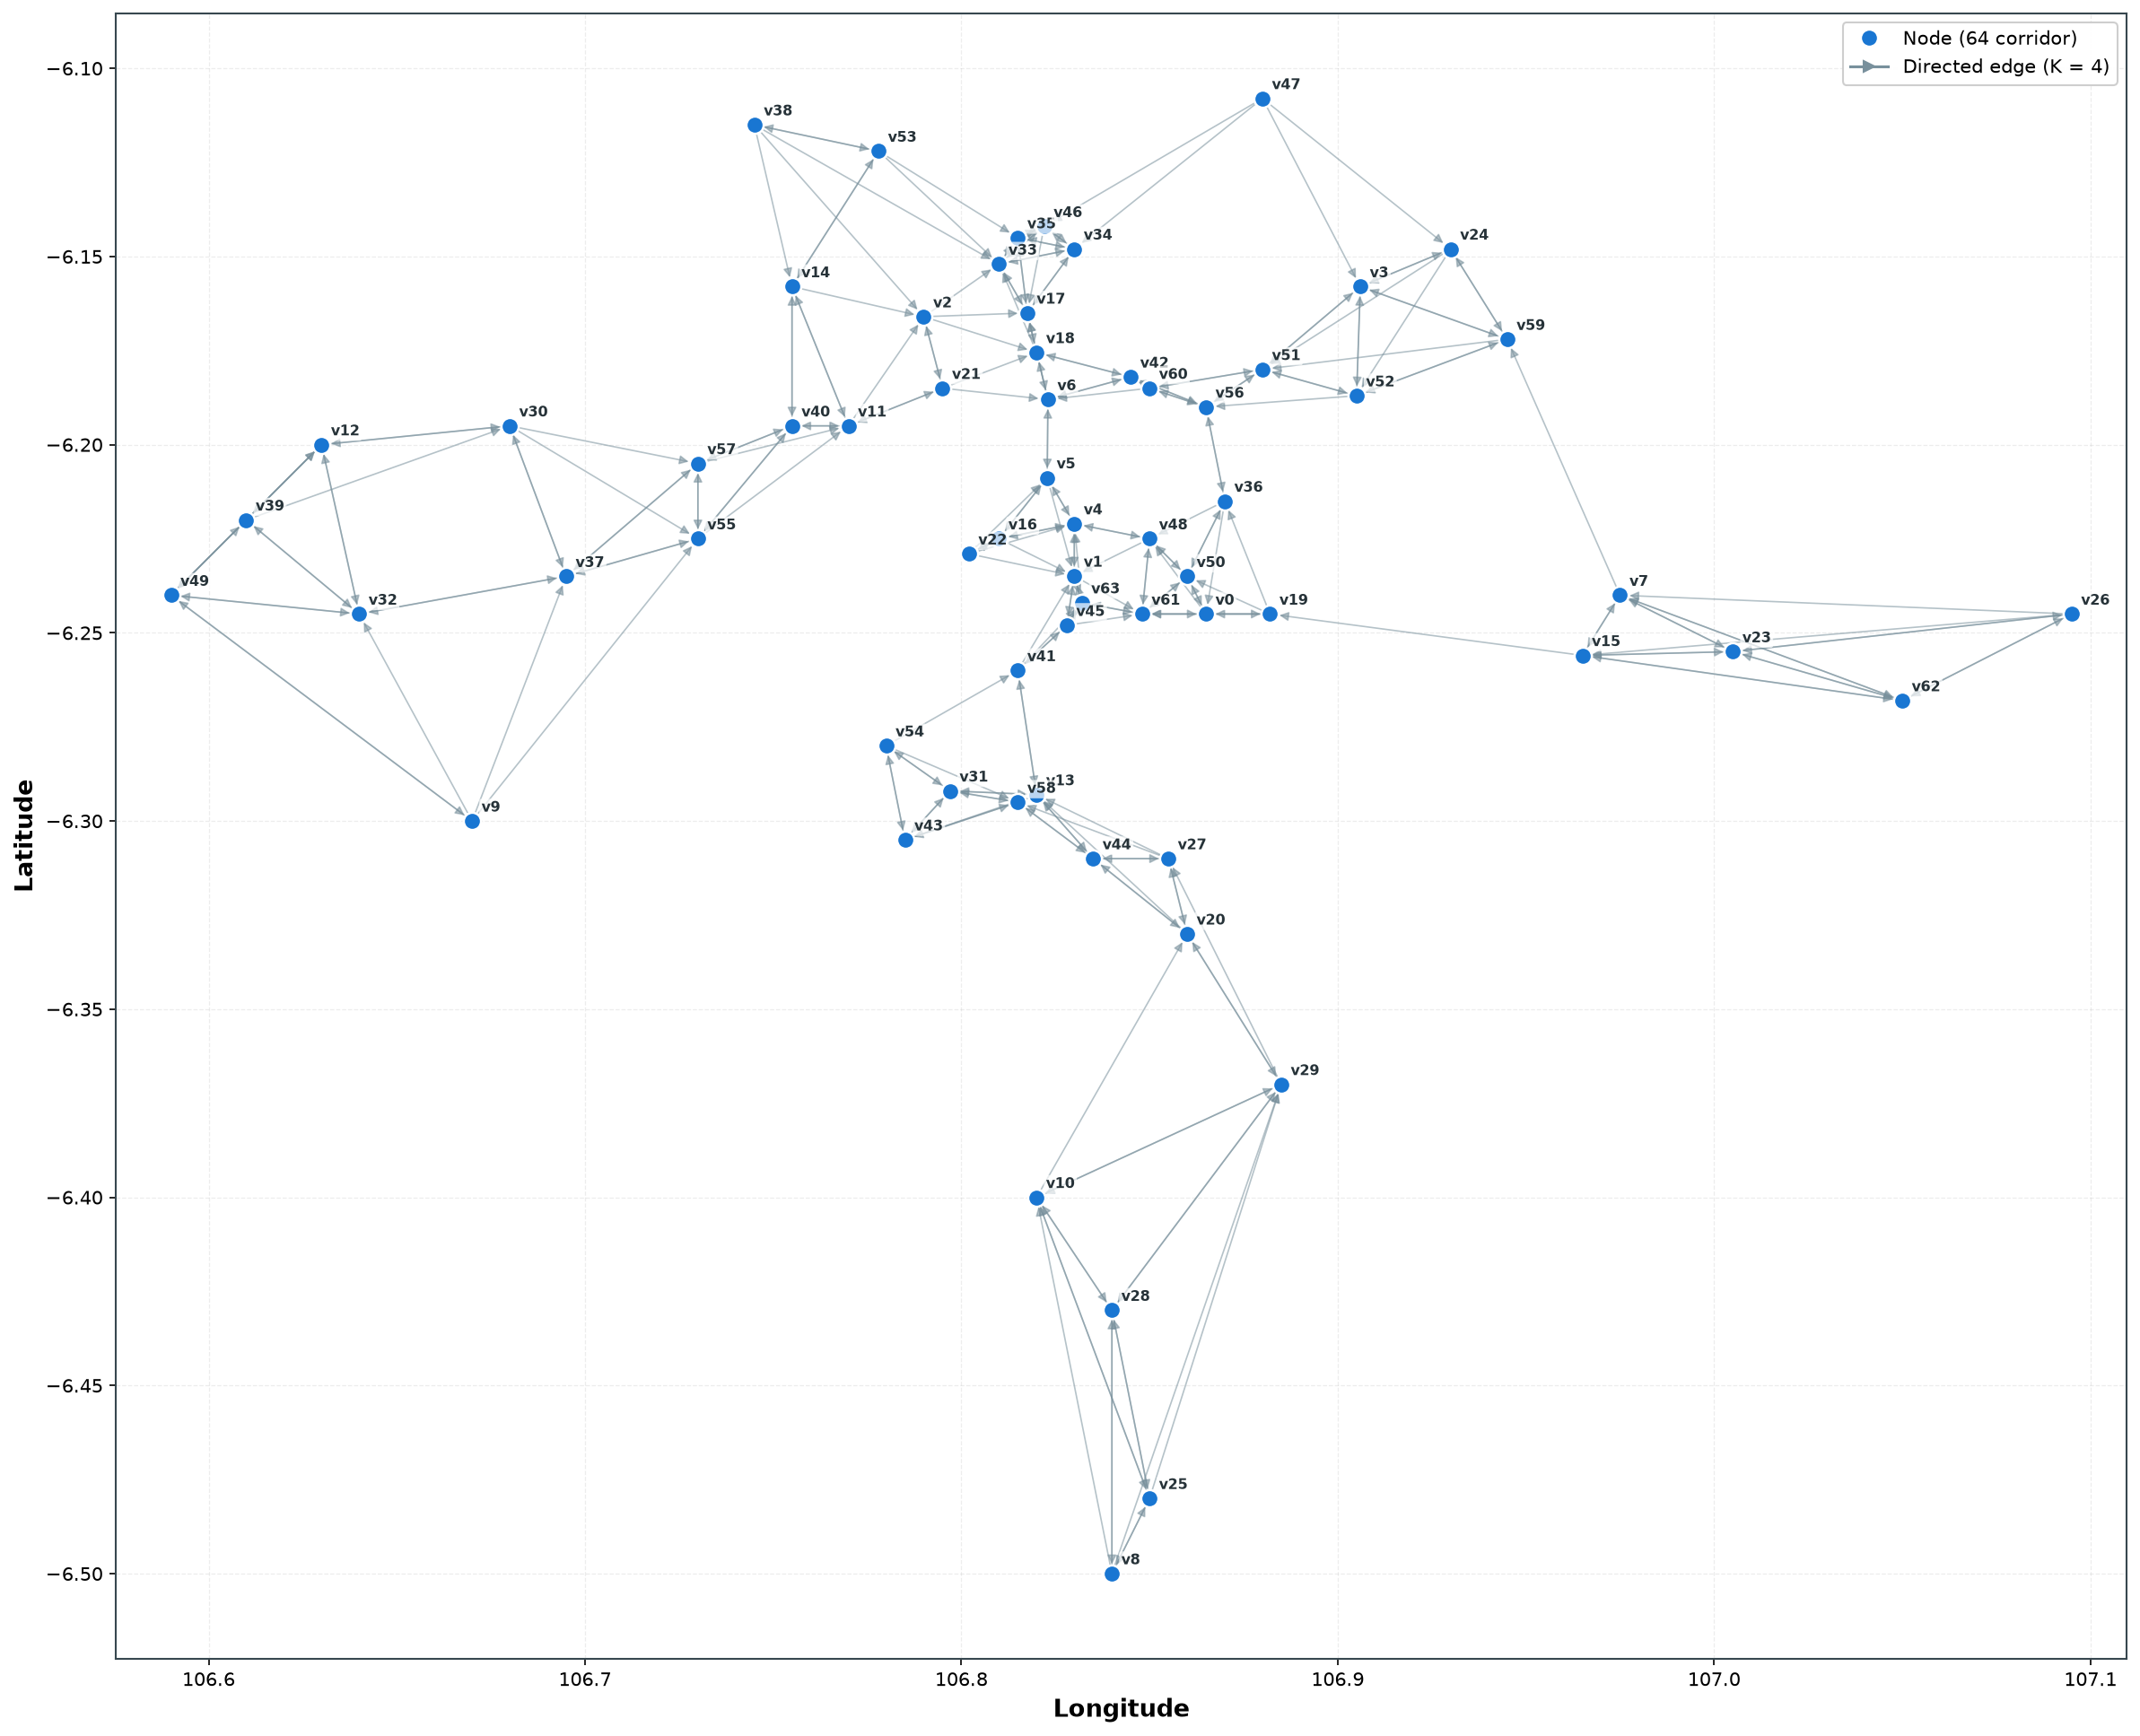

Saved HD: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/fixed_graph_64_nodes.png


In [13]:
# ============================================================
# 7. BUAT FIGURE — VERSI HD
# ============================================================

fig, ax = plt.subplots(figsize=(16, 13), dpi=150)


# ============================================================
# 8. GAMBAR DIRECTED EDGES
# ============================================================

for source in range(N):
    targets = np.where(knn_adjacency[source] > 0)[0]

    for target in targets:
        x1 = longitude[source]
        y1 = latitude[source]

        x2 = longitude[target]
        y2 = latitude[target]

        arrow = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="-|>",
            # Arrow lebih terlihat
            mutation_scale=10,
            linewidth=0.8,
            # Biru-keabu agar edge tetap terlihat
            # tapi tidak mengalahkan node
            color="#78909C",
            alpha=0.55,
            shrinkA=5,
            shrinkB=5,
            zorder=1,
        )

        ax.add_patch(arrow)


# ============================================================
# 9. GAMBAR NODE
# ============================================================

ax.scatter(
    longitude,
    latitude,
    # Node dibuat lebih besar
    s=85,
    # Warna node
    facecolors="#1976D2",
    # Border node
    edgecolors="white",
    linewidths=1.2,
    zorder=3,
)


# ============================================================
# 10. LABEL NODE
# ============================================================

for _, row in corridor_df.iterrows():
    ax.annotate(
        f"v{int(row['node_index'])}",
        (float(row["longitude"]), float(row["latitude"])),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7.5,
        fontweight="bold",
        color="#263238",
        # Background putih transparan supaya label
        # tetap terbaca di area graph yang padat
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.70),
        zorder=4,
    )


# ============================================================
# 11. FORMAT AXIS
# ============================================================

ax.set_xlabel("Longitude", fontsize=13, fontweight="bold")

ax.set_ylabel("Latitude", fontsize=13, fontweight="bold")

ax.tick_params(axis="both", labelsize=10)

ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.22)

ax.set_axisbelow(True)

ax.set_aspect("equal", adjustable="datalim")


# ============================================================
# 12. LEGEND
# ============================================================

node_legend = Line2D(
    [0],
    [0],
    marker="o",
    linestyle="None",
    markerfacecolor="#1976D2",
    markeredgecolor="white",
    markersize=9,
    label="Node (64 corridor)",
)

edge_legend = Line2D(
    [0],
    [0],
    color="#78909C",
    linewidth=1.5,
    marker=">",
    markevery=[1],
    markersize=6,
    label="Directed edge (K = 4)",
)

ax.legend(
    handles=[node_legend, edge_legend],
    loc="upper right",
    fontsize=10,
    frameon=True,
    framealpha=0.95,
)


# ============================================================
# 13. BORDER
# ============================================================

for spine in ax.spines.values():
    spine.set_linewidth(1.0)
    spine.set_color("#37474F")


# ============================================================
# 14. SAVE HD
# ============================================================

output_path = root / "fixed_graph_64_nodes.png"

plt.tight_layout()

plt.savefig(
    output_path,
    # 600 DPI untuk naskah skripsi
    dpi=600,
    bbox_inches="tight",
    # Jangan transparan supaya aman ketika masuk Word/PDF
    transparent=False,
    facecolor="white",
)

plt.show()

print("Saved HD:", output_path)

### Gambar 3.6 Pembentukan Subset Graph untuk Pengujian Scalability

Visualisasi berikut menunjukkan pembentukan subset graph yang digunakan dalam pengujian scalability, yaitu **8, 16, 32, dan 64 node**. Pembentukan subset dilakukan secara nested sehingga seluruh node pada subset yang lebih kecil tetap terdapat pada subset berikutnya, yaitu $V_{8} \subset V_{16} \subset V_{32} \subset V_{64}$.

Node pusat dipilih berdasarkan node dengan rata-rata jarak geografis terkecil terhadap seluruh node, yaitu **Kuningan (v4)**. Node lainnya kemudian diurutkan berdasarkan jarak geografis dari node pusat sehingga cakupan graph berkembang secara bertahap dari area sekitar Kuningan menuju graph penuh. Pada setiap ukuran subset, struktur **directed K-Nearest Neighbors (KNN) dengan K = 4** dibentuk kembali menggunakan distance matrix dari node yang termasuk dalam subset tersebut.

Project root: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent
Jumlah corridor: 64
Distance matrix: (64, 64)
Nested subset audit PASSED
V8 ⊂ V16 ⊂ V32 ⊂ V64
 8 node |  32 directed edges | self-loop = 0 | out-degree = [4]
16 node |  64 directed edges | self-loop = 0 | out-degree = [4]
32 node | 128 directed edges | self-loop = 0 | out-degree = [4]
64 node | 256 directed edges | self-loop = 0 | out-degree = [4]


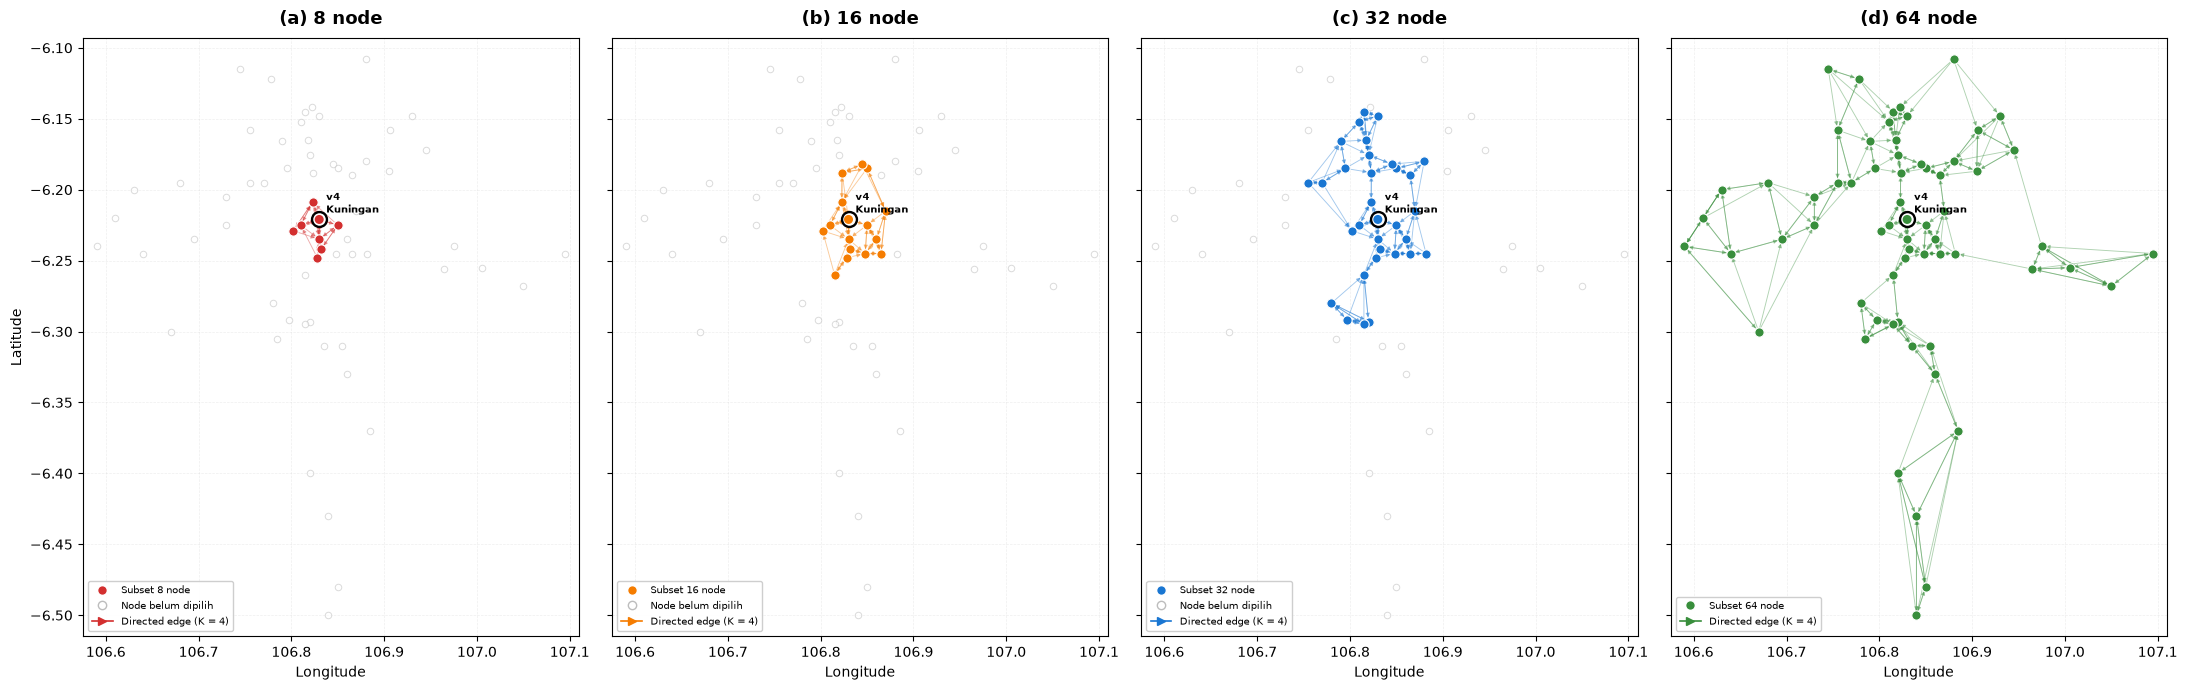

Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/scalability_graph_8_16_32_64.png


In [14]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch


# ============================================================
# 1. PROJECT ROOT
# ============================================================

current = Path.cwd().resolve()
root = current

while root != root.parent:
    if (root / "streamlit_app").exists() and (root / "outputs").exists():
        break
    root = root.parent

if not (root / "streamlit_app").exists():
    raise FileNotFoundError("Project root tidak ditemukan.")

print("Project root:", root)

if str(root) not in sys.path:
    sys.path.insert(0, str(root))


# ============================================================
# 2. LOAD METADATA 64 CORRIDOR
# ============================================================

from streamlit_app.data_loader import get_corridor_metadata

corridor_df = get_corridor_metadata().copy()

corridor_df = corridor_df.sort_values("node_index").reset_index(drop=True)

required_columns = {"node_index", "corridor_name", "latitude", "longitude"}

missing = required_columns - set(corridor_df.columns)

if missing:
    raise ValueError(f"Kolom metadata yang dibutuhkan tidak tersedia: {missing}")

print("Jumlah corridor:", len(corridor_df))


# ============================================================
# 3. LOAD DISTANCE MATRIX
# ============================================================

graph_path = root / "outputs" / "final_64" / "fixed_graph" / "fixed_graph_64.npz"

graph_data = np.load(graph_path)

distance_matrix = graph_data["distance_matrix"]

print("Distance matrix:", distance_matrix.shape)


# ============================================================
# 4. URUTAN NODE SCALABILITY AKTUAL
#
# Center = v4 = Kuningan
# Urutan berdasarkan jarak geografis dari center.
# ============================================================

node_order = [
    4,
    1,
    5,
    48,
    16,
    63,
    45,
    22,
    61,
    50,
    6,
    36,
    60,
    41,
    42,
    0,
    18,
    56,
    21,
    19,
    17,
    51,
    11,
    2,
    33,
    13,
    34,
    58,
    54,
    35,
    31,
    40,
    46,
    52,
    44,
    27,
    43,
    14,
    3,
    55,
    57,
    53,
    20,
    24,
    47,
    59,
    37,
    38,
    15,
    7,
    30,
    29,
    23,
    9,
    10,
    32,
    12,
    28,
    39,
    62,
    49,
    25,
    26,
    8,
]

sizes = [8, 16, 32, 64]

subsets = {size: node_order[:size] for size in sizes}


# ============================================================
# 5. AUDIT NESTED SUBSET
# ============================================================

assert set(subsets[8]).issubset(set(subsets[16]))
assert set(subsets[16]).issubset(set(subsets[32]))
assert set(subsets[32]).issubset(set(subsets[64]))

assert len(set(subsets[64])) == 64

print("Nested subset audit PASSED")
print("V8 ⊂ V16 ⊂ V32 ⊂ V64")


# ============================================================
# 6. FUNGSI REBUILD DIRECTED KNN K=4
# ============================================================


def build_subset_knn(nodes, distance_matrix, k=4):

    nodes = np.asarray(nodes, dtype=int)

    # Distance matrix hanya untuk node dalam subset
    D = distance_matrix[np.ix_(nodes, nodes)].copy()

    n = len(nodes)

    adjacency = np.zeros((n, n), dtype=np.float32)

    for i in range(n):
        distances = D[i].copy()

        # Hindari self-loop
        distances[i] = np.inf

        nearest = np.argsort(distances)[:k]

        adjacency[i, nearest] = 1.0

    return adjacency


# ============================================================
# 7. BUILD + AUDIT SEMUA SUBSET
# ============================================================

subset_graphs = {}

for size in sizes:
    nodes = subsets[size]

    A = build_subset_knn(nodes, distance_matrix, k=4)

    subset_graphs[size] = A

    edges = int(np.count_nonzero(A))
    self_loops = int(np.count_nonzero(np.diag(A)))
    out_degree = np.count_nonzero(A, axis=1)

    print(
        f"{size:>2} node | "
        f"{edges:>3} directed edges | "
        f"self-loop = {self_loops} | "
        f"out-degree = {np.unique(out_degree)}"
    )

    assert edges == size * 4
    assert self_loops == 0
    assert np.all(out_degree == 4)


# ============================================================
# 8. KOORDINAT GLOBAL
# ============================================================

longitude = corridor_df["longitude"].to_numpy(dtype=float)
latitude = corridor_df["latitude"].to_numpy(dtype=float)

x_min = longitude.min() - 0.015
x_max = longitude.max() + 0.015

y_min = latitude.min() - 0.015
y_max = latitude.max() + 0.015


# ============================================================
# 9. WARNA UNTUK SETIAP UKURAN
# ============================================================

subset_colors = {8: "#D32F2F", 16: "#F57C00", 32: "#1976D2", 64: "#388E3C"}


# ============================================================
# 10. BUAT 4 PANEL
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(22, 7), sharex=True, sharey=True)

panel_labels = {8: "(a) 8 node", 16: "(b) 16 node", 32: "(c) 32 node", 64: "(d) 64 node"}


# ============================================================
# 11. DRAW SETIAP SUBSET
# ============================================================

for ax, size in zip(axes, sizes):
    selected = subsets[size]

    selected_set = set(selected)

    A = subset_graphs[size]

    color = subset_colors[size]

    # --------------------------------------------------------
    # NODE YANG BELUM MASUK SUBSET
    # --------------------------------------------------------

    if size < 64:
        remaining = [i for i in range(64) if i not in selected_set]

        ax.scatter(
            longitude[remaining],
            latitude[remaining],
            s=22,
            facecolors="white",
            edgecolors="#BDBDBD",
            linewidths=0.7,
            alpha=0.55,
            zorder=1,
        )

    # --------------------------------------------------------
    # DIRECTED EDGES SUBSET
    # --------------------------------------------------------

    for local_source in range(size):
        global_source = selected[local_source]

        targets = np.where(A[local_source] > 0)[0]

        for local_target in targets:
            global_target = selected[local_target]

            arrow = FancyArrowPatch(
                (longitude[global_source], latitude[global_source]),
                (longitude[global_target], latitude[global_target]),
                arrowstyle="-|>",
                mutation_scale=6,
                linewidth=0.65,
                color=color,
                alpha=0.40,
                shrinkA=3,
                shrinkB=3,
                zorder=2,
            )

            ax.add_patch(arrow)

    # --------------------------------------------------------
    # SELECTED NODES
    # --------------------------------------------------------

    ax.scatter(
        longitude[selected],
        latitude[selected],
        s=45,
        facecolors=color,
        edgecolors="white",
        linewidths=0.8,
        zorder=3,
    )

    # --------------------------------------------------------
    # CENTER NODE v4 / KUNINGAN
    # --------------------------------------------------------

    center_node = 4

    ax.scatter(
        longitude[center_node],
        latitude[center_node],
        s=115,
        facecolors="white",
        edgecolors="black",
        linewidths=1.7,
        zorder=5,
    )

    ax.scatter(
        longitude[center_node],
        latitude[center_node],
        s=42,
        facecolors=color,
        edgecolors="none",
        zorder=6,
    )

    ax.annotate(
        "v4\nKuningan",
        (longitude[center_node], latitude[center_node]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7.5,
        fontweight="bold",
        zorder=7,
    )

    # --------------------------------------------------------
    # FORMAT PANEL
    # --------------------------------------------------------

    ax.set_title(panel_labels[size], fontsize=13, fontweight="bold", pad=10)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.20)

    ax.set_axisbelow(True)

    ax.set_xlabel("Longitude", fontsize=10)


# ============================================================
# 12. Y LABEL
# ============================================================

axes[0].set_ylabel("Latitude", fontsize=10)


# ============================================================
# 13. LEGEND
# ============================================================

for ax, size in zip(axes, sizes):
    color = subset_colors[size]

    selected_legend = Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor=color,
        markeredgecolor="white",
        markersize=7,
        label=f"Subset {size} node",
    )

    edge_legend = Line2D(
        [0],
        [0],
        color=color,
        linewidth=1.2,
        marker=">",
        markevery=[1],
        label="Directed edge (K = 4)",
    )

    handles = [selected_legend, edge_legend]

    if size < 64:
        remaining_legend = Line2D(
            [0],
            [0],
            marker="o",
            linestyle="None",
            markerfacecolor="white",
            markeredgecolor="#BDBDBD",
            markersize=6,
            label="Node belum dipilih",
        )

        handles.insert(1, remaining_legend)

    ax.legend(handles=handles, loc="lower left", fontsize=7.5, frameon=True, framealpha=0.95)


# ============================================================
# 14. SAVE HD
# ============================================================

output_path = root / "scalability_graph_8_16_32_64.png"

plt.tight_layout()

plt.savefig(output_path, dpi=600, bbox_inches="tight", facecolor="white", transparent=False)

plt.show()

print("Saved:", output_path)